# Análise de Vendas Para Loja de E-commerce com NumPy, Pandas e Matplotlib

> ⚠️ **Dados fictícios.** O dataset é gerado em Python (notebook `geracao_dataset.ipynb`). Sazonalidade, variação entre meses, distribuição por estado e base de clientes foram **simuladas**.

## 1. Definição do Problema de Negócio

**1.1. O Problema de Negócio**

Nossa loja de e-commerce está em fase de crescimento, registrando um volume cada vez maior de transações diárias. No entanto, essa grande quantidade de dados de vendas, em seu estado bruto, é como um baú de tesouro trancado: sabemos que há valor ali, mas não conseguimos acessá-lo.

Atualmente, muitas de nossas decisões estratégicas são baseadas em intuição e observações parciais, o que nos leva a enfrentar os seguintes desafios:

- Gestão de Estoque Ineficiente: Não temos clareza sobre quais produtos são nossos "campeões de venda" e quais estão parados nas prateleiras. Isso resulta em excesso de estoque de itens de baixa procura e falta de produtos de alta demanda.

- Marketing com Baixo Retorno: Nossas campanhas de marketing são genéricas, pois não sabemos quais categorias de produtos atraem mais os clientes ou em quais regiões geográficas nosso público está mais concentrado.

- Perda de Oportunidades Sazonais: Não conseguimos identificar padrões ou tendências de vendas ao longo dos meses. Isso nos impede de planejar promoções estratégicas para períodos de alta ou de criar ações para impulsionar as vendas em meses de baixa.

- Expansão sem Direção: Temos o desejo de expandir, mas não sabemos quais mercados regionais são mais promissores ou onde nossos esforços logísticos deveriam ser focados.

O problema central é a falta de visibilidade clara sobre a performance do negócio, o que nos impede de tomar decisões rápidas, inteligentes e baseadas em evidências.

**1.2. Objetivos do Projeto**

Este projeto de análise de dados visa transformar nossos dados brutos de vendas em insights acionáveis. O objetivo é responder a quatro perguntas de negócio fundamentais:

- O que vender? Identificar os produtos de maior sucesso para otimizar nosso portfólio e estoque.
<!-- Trabalho Desenvolvido no Curso da Data Science Academy - www.datascienceacademy.com.br -->
- Onde focar? Compreender quais categorias de produtos geram a maior parte da nossa receita.

- Quando agir? Analisar a performance de vendas ao longo do tempo para identificar tendências, picos e sazonalidades.

- Para onde expandir? Mapear a distribuição geográfica de nossas vendas para descobrir nossos mercados mais fortes.

**1.3. Solução Proposta**

A solução consiste em consolidar, limpar e analisar o histórico de dados de vendas da nossa plataforma. Utilizando ferramentas de análise de dados (como Python com Pandas, NumPy e Matplotlib), vamos processar essas informações e criar um relatório visual que apresente as descobertas de forma clara e intuitiva para as equipes de gestão, marketing e operações.

**1.4. Resultados Esperados e Benefícios de Negócio**

Ao final deste projeto, esperamos alcançar os seguintes resultados:

- Otimização de Estoque: Com a lista dos produtos mais e menos vendidos, poderemos ajustar nossas compras, reduzir custos com armazenamento e evitar a perda de vendas por falta de produto.

- Marketing Direcionado e Eficaz: Sabendo quais categorias e regiões são mais lucrativas, a equipe de marketing poderá criar campanhas segmentadas, aumentando o retorno sobre o investimento (ROI).

- Planejamento Estratégico: A visualização das tendências mensais permitirá um melhor planejamento financeiro, promocional e de recursos, antecipando períodos de alta e baixa demanda.

- Decisões Baseadas em Dados: Substituiremos a intuição por dados concretos, criando uma cultura orientada a dados que impulsionará o crescimento sustentável do negócio.

## 2. Importação das Bibliotecas

In [1]:
import pandas as pd
import pandas_gbq
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
from datetime import datetime, timedelta
from matplotlib.ticker import FuncFormatter
%matplotlib inline

# Instalação (rodar uma vez, se necessário):
# %pip install pandas-gbq

## 3. Carregar e Explorar os Dados

In [2]:
df = pd.read_csv("vendas_raw.csv", parse_dates=["Data_Pedido"])

In [3]:
print(df.shape)

(707161, 9)


In [4]:
 df.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado
0,1000,2026-01-01 23:00:00,Teclado Mecânico,Acessórios,538.81,7,104694,São Paulo,SP
1,1001,2026-01-01 17:00:00,Laptop Gamer,Eletrônicos,7500.00,3,120879,Porto Alegre,RS
2,1002,2026-01-01 00:00:00,Laptop Gamer,Eletrônicos,7500.00,5,55886,Rio de Janeiro,RJ
3,1003,2026-01-01 19:00:00,Laptop Gamer,Eletrônicos,7500.00,2,88498,São Paulo,SP
4,1004,2026-01-01 20:00:00,Laptop Gamer,Eletrônicos,7500.00,5,17023,São Paulo,SP


In [5]:
type(df)

pandas.core.frame.DataFrame

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 707161 entries, 0 to 707160
Data columns (total 9 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   ID_Pedido       707161 non-null  int64         
 1   Data_Pedido     707161 non-null  datetime64[ns]
 2   Nome_Produto    707161 non-null  object        
 3   Categoria       707161 non-null  object        
 4   Preco_Unitario  707161 non-null  float64       
 5   Quantidade      707161 non-null  int64         
 6   ID_Cliente      707161 non-null  int64         
 7   Cidade          707161 non-null  object        
 8   Estado          707161 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(3), object(4)
memory usage: 48.6+ MB


In [7]:
df["Data_Pedido"] = pd.to_datetime(df["Data_Pedido"])

In [8]:
df["Faturamento"] = df["Preco_Unitario"] * df["Quantidade"]

In [9]:
df.head()

,ID_Pedido,Data_Pedido,Nome_Produto,Categoria,Preco_Unitario,Quantidade,ID_Cliente,Cidade,Estado,Faturamento
0,1000,2026-01-01 23:00:00,Teclado Mecânico,Acessórios,538.81,7,104694,São Paulo,SP,3771.67
1,1001,2026-01-01 17:00:00,Laptop Gamer,Eletrônicos,7500.00,3,120879,Porto Alegre,RS,22500.00
2,1002,2026-01-01 00:00:00,Laptop Gamer,Eletrônicos,7500.00,5,55886,Rio de Janeiro,RJ,37500.00
3,1003,2026-01-01 19:00:00,Laptop Gamer,Eletrônicos,7500.00,2,88498,São Paulo,SP,15000.00
4,1004,2026-01-01 20:00:00,Laptop Gamer,Eletrônicos,7500.00,5,17023,São Paulo,SP,37500.00


## Análise 01: ranking de produtos por quantidade vendida

In [10]:
df_10_produtos = ( 
    df.groupby("Nome_Produto")["Quantidade"]
    .sum()
    .reset_index()
    .sort_values(by="Quantidade", ascending=False)
)
df_10_produtos

,Nome_Produto,Quantidade
7,Teclado Mecânico,362508
2,Laptop Gamer,362235
3,Monitor Ultrawide,360601
1,Headset 7.1,359765
4,Mouse Vertical,359685
6,SSD 1TB,343050
0,Cadeira Gamer,340152
5,Placa de Vídeo,338657


## Gráfico da Análise 01

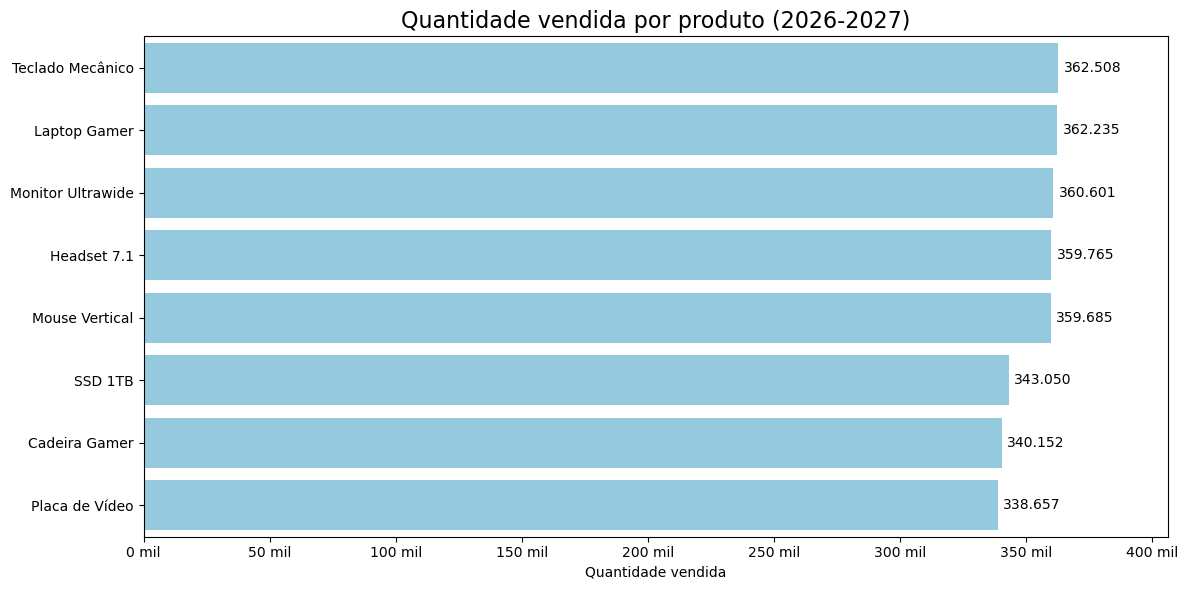

In [11]:
dados = df_10_produtos.sort_values(by="Quantidade", ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=dados, x="Quantidade", y="Nome_Produto", color="skyblue", ax=ax)

# Rótulos com separador de milhar e espaço à direita para não cortar
ax.bar_label(ax.containers[0],
             labels=[f"{v:,.0f}".replace(",", ".") for v in dados["Quantidade"]],
             padding=4)
ax.set_xlim(0, dados["Quantidade"].max() * 1.12)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v/1000:,.0f} mil"))

ax.set_title("Quantidade vendida por produto (2026-2027)", fontsize=16)
ax.set_xlabel("Quantidade vendida")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## Análise 02: Ranking quantidade vendida por categoria

In [12]:
df_10_categorias = ( 
    df.groupby("Categoria")["Quantidade"]
    .sum()
    .reset_index()
    .sort_values(by = "Quantidade", ascending = False)
)
df_10_categorias

,Categoria,Quantidade
0,Acessórios,1081958
1,Eletrônicos,722836
2,Hardware,681707
3,Móveis,340152


## Análise 03: Ranking de faturamento por categoria

In [13]:
# análise: ranking de categoria por faturamento total
df_10_categorias_faturamento = (
    df.groupby("Categoria")["Faturamento"]
    .sum()
    .reset_index()
    .sort_values(by='Faturamento', ascending = False)
)
df_10_categorias_faturamento.style.format({"Faturamento": "R$ {:,.2f}"})

,Categoria,Faturamento
1,Eletrônicos,"R$ 3,726,445,300.00"
2,Hardware,"R$ 1,729,786,500.00"
0,Acessórios,"R$ 562,663,825.59"
3,Móveis,"R$ 408,182,400.00"


## Análise 04: Ranking de faturamento por categoria e produtos

In [14]:
fat_cad_prod = (
    df.groupby(["Categoria", "Nome_Produto"])["Faturamento"]
    .sum()
    .reset_index()
    .sort_values(["Categoria", "Faturamento"], ascending=[True, False])
)
fat_cad_prod.style.format({"Faturamento": "R$ {:,.2f}"})

,Categoria,Nome_Produto,Faturamento
0,Acessórios,Headset 7.1,"R$ 287,812,000.00"
2,Acessórios,Teclado Mecânico,"R$ 189,421,523.71"
1,Acessórios,Mouse Vertical,"R$ 85,430,301.88"
3,Eletrônicos,Laptop Gamer,"R$ 2,716,762,500.00"
4,Eletrônicos,Monitor Ultrawide,"R$ 1,009,682,800.00"
5,Hardware,Placa de Vídeo,"R$ 1,523,956,500.00"
6,Hardware,SSD 1TB,"R$ 205,830,000.00"
7,Móveis,Cadeira Gamer,"R$ 408,182,400.00"


## Análise 05: Faturamento mensal

In [15]:
df['Mês'] = df['Data_Pedido'].dt.to_period('M')
df_fat_mensal = ( 
    df.groupby('Mês')['Faturamento']
    .sum()
    .reset_index()
)
df_fat_mensal.style.format({"Faturamento": "R$ {:,.2f}"})

,Mês,Faturamento
0,2026-01,"R$ 228,049,705.95"
1,2026-02,"R$ 204,090,718.84"
2,2026-03,"R$ 268,163,565.97"
3,2026-04,"R$ 227,937,084.50"
4,2026-05,"R$ 254,941,465.74"
5,2026-06,"R$ 270,470,353.81"
6,2026-07,"R$ 228,517,134.65"
7,2026-08,"R$ 269,022,308.59"
8,2026-09,"R$ 218,682,211.18"
9,2026-10,"R$ 282,707,799.37"


## Gráfico da Análise 05

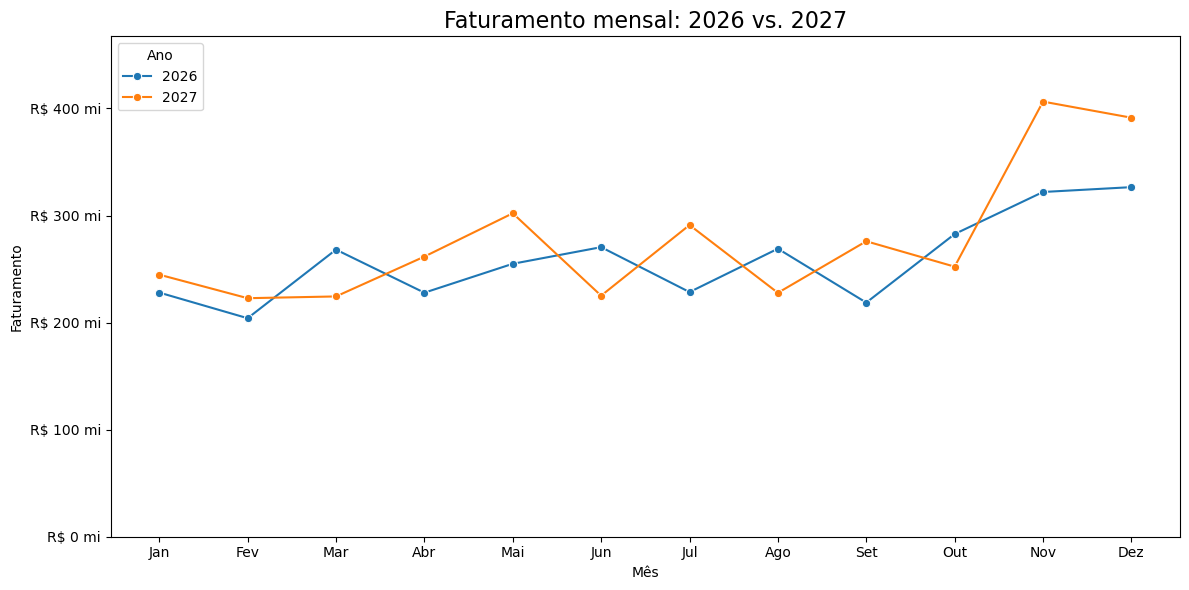

In [16]:
d = df.copy()
d["Ano"] = d["Data_Pedido"].dt.year.astype(str)
d["Mes_Num"] = d["Data_Pedido"].dt.month

fat = d.groupby(["Ano", "Mes_Num"])["Faturamento"].sum().reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=fat, x="Mes_Num", y="Faturamento", hue="Ano", marker="o", ax=ax)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"R$ {v/1e6:,.0f} mi"))
ax.set_ylim(0, fat["Faturamento"].max() * 1.15)

ax.set_title("Faturamento mensal: 2026 vs. 2027", fontsize=16)
ax.set_xlabel("Mês")
ax.set_ylabel("Faturamento")
plt.tight_layout()
plt.show()

## Análise 06: Faturamento e quantidade vendida por estado

In [17]:
df_vendas_uf =(
    df.groupby('Estado')[['Faturamento', 'Quantidade']]
    .sum()
    .reset_index()
    .sort_values(by="Faturamento", ascending=False)
)
df_vendas_uf.style.format({"Faturamento": "R$ {:,.2f}"})

,Estado,Faturamento,Quantidade
6,SP,"R$ 2,257,242,627.14",990428
4,RJ,"R$ 1,152,876,370.17",509100
2,MG,"R$ 968,425,653.52",426036
3,PR,"R$ 637,693,933.55",280393
5,RS,"R$ 572,487,918.56",253258
0,BA,"R$ 517,356,395.23",226866
1,CE,"R$ 320,995,127.42",140572


## Análise 07: Faturamento e quantidade vendida por categoria

In [18]:
df_vendas_cat = ( 
    df.groupby('Categoria')[['Faturamento', 'Quantidade']]
    .sum()
    .reset_index()
    .sort_values(by= 'Faturamento', ascending= False)
)
df_vendas_cat.style.format({"Faturamento": "R$ {:,.2f}"})

,Categoria,Faturamento,Quantidade
1,Eletrônicos,"R$ 3,726,445,300.00",722836
2,Hardware,"R$ 1,729,786,500.00",681707
0,Acessórios,"R$ 562,663,825.59",1081958
3,Móveis,"R$ 408,182,400.00",340152


## 5. Carga do dataframe no BigQuery

### O DataFrame tratado é gravado no BigQuery para consumo por SQL e pelo Looker Studio. Para reproduzir, substitua PROJECT_ID pelo seu projeto e autentique com sua conta Google.

In [19]:
df_bq = df.copy()

def limpa_nome(col):
    col = unicodedata.normalize("NFKD", col).encode("ascii", "ignore").decode("ascii")
    return col.strip().lower().replace(" ", "_")

df_bq.columns = [limpa_nome(c) for c in df_bq.columns]

df_bq["mes"] = df_bq["mes"].dt.to_timestamp()

df_bq.dtypes

id_pedido                  int64
data_pedido       datetime64[ns]
nome_produto              object
categoria                 object
preco_unitario           float64
quantidade                 int64
id_cliente                 int64
cidade                    object
estado                    object
faturamento              float64
mes               datetime64[ns]
dtype: object

In [20]:
PROJECT_ID = "ecommerce-analytics-514821"
TABELA = "ecommerce_analytics.vendas"

pandas_gbq.to_gbq(
    df_bq,
    destination_table=TABELA,
    project_id=PROJECT_ID,
    if_exists="replace",
)

100%|█████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00, 14665.40it/s]


In [21]:
consulta = f"""
SELECT COUNT(*) AS linhas,
       ROUND(SUM(faturamento), 2) AS faturamento_total
FROM `{PROJECT_ID}.{TABELA}`
"""
resultado = pandas_gbq.read_gbq(consulta, project_id=PROJECT_ID)
print(resultado)
print("No DataFrame:", len(df_bq), "linhas |", round(df_bq["faturamento"].sum(), 2))

Downloading: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████|
   linhas  faturamento_total
0  707161       6.427078e+09
No DataFrame: 707161 linhas | 6427078025.59
